In [1]:
#importation des bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [4]:

df = pd.read_csv('HRDataset_v14.csv')
print(df.head)

<bound method NDFrame.head of                 Employee_Name  EmpID  MarriedID  MaritalStatusID  GenderID  \
0         Adinolfi, Wilson  K  10026          0                0         1   
1    Ait Sidi, Karthikeyan     10084          1                1         1   
2           Akinkuolie, Sarah  10196          1                1         0   
3                Alagbe,Trina  10088          1                1         0   
4            Anderson, Carol   10069          0                2         0   
..                        ...    ...        ...              ...       ...   
306            Woodson, Jason  10135          0                0         1   
307        Ybarra, Catherine   10301          0                0         0   
308          Zamora, Jennifer  10010          0                0         0   
309               Zhou, Julia  10043          0                0         0   
310             Zima, Colleen  10271          0                4         0   

     EmpStatusID  DeptID  PerfSco

In [8]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 36 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Employee_Name               311 non-null    object 
 1   EmpID                       311 non-null    int64  
 2   MarriedID                   311 non-null    int64  
 3   MaritalStatusID             311 non-null    int64  
 4   GenderID                    311 non-null    int64  
 5   EmpStatusID                 311 non-null    int64  
 6   DeptID                      311 non-null    int64  
 7   PerfScoreID                 311 non-null    int64  
 8   FromDiversityJobFairID      311 non-null    int64  
 9   Salary                      311 non-null    int64  
 10  Termd                       311 non-null    int64  
 11  PositionID                  311 non-null    int64  
 12  Position                    311 non-null    object 
 13  State                       311 non

In [10]:
print(df.describe())

              EmpID   MarriedID  MaritalStatusID    GenderID  EmpStatusID  \
count    311.000000  311.000000       311.000000  311.000000   311.000000   
mean   10156.000000    0.398714         0.810289    0.434084     2.392283   
std       89.922189    0.490423         0.943239    0.496435     1.794383   
min    10001.000000    0.000000         0.000000    0.000000     1.000000   
25%    10078.500000    0.000000         0.000000    0.000000     1.000000   
50%    10156.000000    0.000000         1.000000    0.000000     1.000000   
75%    10233.500000    1.000000         1.000000    1.000000     5.000000   
max    10311.000000    1.000000         4.000000    1.000000     5.000000   

           DeptID  PerfScoreID  FromDiversityJobFairID         Salary  \
count  311.000000   311.000000              311.000000     311.000000   
mean     4.610932     2.977492                0.093248   69020.684887   
std      1.083487     0.587072                0.291248   25156.636930   
min      1.000

In [15]:
# Sélection des colonnes numériques clés dans HRDataset
colonnes_a_analyser = ['PerfScoreID', 'Absences']

print("=" * 50)
print("STATISTIQUES DESCRIPTIVES - HR DATASET")
print("=" * 50)

for col in colonnes_a_analyser:
    print(f"\n Analyse pour la variable : {col}")
    print("-" * 40)

    # 1. Tendance centrale
    moyenne = df[col].mean()
    mediane = df[col].median()
    mode = df[col].mode().values

    print(f"• Moyenne (Mean)   : {moyenne:.2f}")
    print(f"• Médiane (Median) : {mediane:.2f}")
    print(f"• Mode(s)          : {mode}")

    # 2. Dispersion et Quartiles
    q25 = df[col].quantile(0.25)
    q75 = df[col].quantile(0.75)
    variance = df[col].var()
    ecart_type = df[col].std()

    print(f"• 1er Quartile (Q1): {q25:.2f}")
    print(f"• 3ème Quartile (Q3): {q75:.2f}")
    print(f"• Variance         : {variance:.2f}")
    print(f"• Écart-type (Std) : {ecart_type:.2f}")

STATISTIQUES DESCRIPTIVES - HR DATASET

 Analyse pour la variable : PerfScoreID
----------------------------------------
• Moyenne (Mean)   : 2.98
• Médiane (Median) : 3.00
• Mode(s)          : [3]
• 1er Quartile (Q1): 3.00
• 3ème Quartile (Q3): 3.00
• Variance         : 0.34
• Écart-type (Std) : 0.59

 Analyse pour la variable : Absences
----------------------------------------
• Moyenne (Mean)   : 10.24
• Médiane (Median) : 10.00
• Mode(s)          : [ 4 16]
• 1er Quartile (Q1): 5.00
• 3ème Quartile (Q3): 15.00
• Variance         : 34.25
• Écart-type (Std) : 5.85


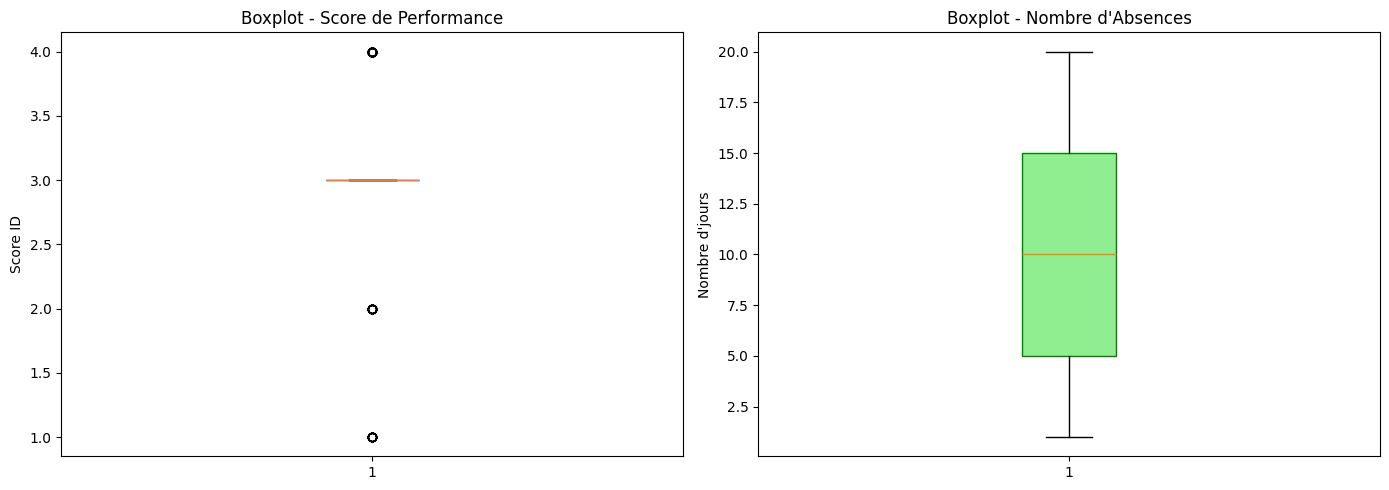

In [16]:
# Création d'une figure avec 2 graphiques côte à côte (1 ligne, 2 colonnes)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# 1. Boxplot pour le score de performance (PerfScoreID)
axes[0].boxplot(df['PerfScoreID'].dropna(), vert=True, patch_artist=True,
                boxprops=dict(facecolor='skyblue', color='blue'))
axes[0].set_title('Boxplot - Score de Performance')
axes[0].set_ylabel('Score ID')

# 2. Boxplot pour les absences (Absences)
axes[1].boxplot(df['Absences'].dropna(), vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightgreen', color='green'))
axes[1].set_title('Boxplot - Nombre d\'Absences')
axes[1].set_ylabel('Nombre d\'jours')

# Ajustement de l'affichage et affichage des graphiques
plt.tight_layout()
plt.show()

In [17]:
# Fonction générique pour détecter les outliers avec la règle des 1.5 * IQR
def detecter_outliers(df, nom_colonne):
    Q1 = df[nom_colonne].quantile(0.25)
    Q3 = df[nom_colonne].quantile(0.75)
    IQR = Q3 - Q1

    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    # Filtrer les lignes qui dépassent les bornes
    outliers = df[(df[nom_colonne] < borne_inf) | (df[nom_colonne] > borne_sup)]

    print(f"\n Analyse des Outliers pour : {nom_colonne}")
    print(f"• Q1 = {Q1:.2f} | Q3 = {Q3:.2f} | IQR = {IQR:.2f}")
    print(f"• Bornes acceptables : [{borne_inf:.2f} ; {borne_sup:.2f}]")
    print(f"• Nombre d'outliers détectés : {len(outliers)}")

    return outliers

# 1. Test sur les Absences
outliers_absences = detecter_outliers(df, 'Absences')

# 2. Test sur les Salaires
outliers_salaires = detecter_outliers(df, 'Salary')

# Afficher un aperçu des employés qui ont un salaire "outlier" (les plus hauts salaires)
print("\n--- Aperçu des plus hauts salaires (Outliers hauts) ---")
display(outliers_salaires[['Employee_Name', 'Position', 'Salary']].head(5))


 Analyse des Outliers pour : Absences
• Q1 = 5.00 | Q3 = 15.00 | IQR = 10.00
• Bornes acceptables : [-10.00 ; 30.00]
• Nombre d'outliers détectés : 0

 Analyse des Outliers pour : Salary
• Q1 = 55501.50 | Q3 = 72036.00 | IQR = 16534.50
• Bornes acceptables : [30699.75 ; 96837.75]
• Nombre d'outliers détectés : 29

--- Aperçu des plus hauts salaires (Outliers hauts) ---


,Employee_Name,Position,Salary
1,"Ait Sidi, Karthikeyan",Sr. DBA,104437
18,"Becker, Renee",Database Administrator,110000
25,"Booth, Frank",Enterprise Architect,103613
26,"Boutwell, Bonalyn",Sr. Accountant,106367
39,"Carr, Claudia N",Sr. DBA,100031
